# 02 — Data Preprocessing

## 1. Research Objectives

This notebook establishes the data-preparation protocol for the TopicSense-NLP classification experiments.

Building on the dataset characteristics and integrity findings established in Notebook 01, this phase focuses on preparing reproducible development partitions and defining the text representations that will be evaluated during model development.

The main objectives are to:

1. Generate training and validation partitions that preserve known duplicate relationships.
2. Verify that the resulting partitions satisfy the project's data-separation requirements.
3. Retain distinct evaluation tracks for the official benchmark and contamination sensitivity analyses.
4. Establish consistent full-message and message-body representations.
5. Examine document-length characteristics within the development partitions.
6. Record the preprocessing configuration and generated data profiles for subsequent experiments.

The reusable implementation is maintained in `src/topicsense/preprocessing/`. This notebook documents the implementation's use and examines its outputs rather than introducing a separate preprocessing implementation.

## 2. Methodological Decisions

The following decisions govern this phase:

- The original training and test partitions are preserved.
- Validation data is derived exclusively from the official training partition.
- Duplicate-connected records are kept together when creating development partitions.
- A separate development split is created after excluding the 10 training records implicated in substantive cross-partition exact-body duplication.
- The official test partition is not used to fit preprocessing transformations, build vocabularies, select models or tune hyperparameters.
- Full-message and message-body representations are retained for controlled comparison.
- Unicode NFKC and whitespace normalization are applied conservatively.
- Case, punctuation, numbers, quotations, signatures and stopwords are retained unless a subsequent experiment explicitly evaluates their removal.
- Learned vocabularies, vectorizers, feature weights and tokenizer vocabularies must be fitted on training data only.

Training data is used to learn model parameters. Validation data supports model comparison and development decisions. The official test data remains reserved for final evaluation.

The separation of these roles is essential: a model should not be rewarded during validation for recognising a duplicate of a message it has already encountered during training.

In [21]:
from __future__ import annotations

import json
import random
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

from topicsense.preprocessing import (
    create_preprocessing_splits,
    preprocess_text,
    tokenize_words,
)

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError(
        "Open this notebook with the repository root as the working directory."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))

CONFIG_PATH = PROJECT_ROOT / "configs" / "data.yaml"

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = yaml.safe_load(file)

DATASET_CONFIG = CONFIG["dataset"]
SPLITTING_CONFIG = CONFIG["splitting"]

RANDOM_SEED = int(SPLITTING_CONFIG["random_seed"])
VALIDATION_SIZE = float(SPLITTING_CONFIG["validation_size"])

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset: {DATASET_CONFIG['display_name']}")
print(f"Validation target: {VALIDATION_SIZE:.0%}")
print(f"Random seed: {RANDOM_SEED}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Dataset: 20 Newsgroups
Validation target: 20%
Random seed: 42


## 3. Input Artifacts and Leakage-Aware Split Generation

The split-generation process uses four existing project artifacts:

- The original 20 Newsgroups JSONL dataset.
- The normalized exact-message-body duplicate audit.
- The MinHash/Jaccard near-duplicate report.
- The manifest containing training record IDs excluded from the decontaminated-training sensitivity analysis.

The duplicate reports describe relationships between records. The splitting implementation converts the relevant relationships within the official training partition into connected groups. Records belonging to the same group must remain together when training and validation are separated.

This is important because a conventional random split could place one version of a message in training and a near-identical version in validation. Such a split would make the validation result less representative of the model's ability to classify genuinely unseen material.

The official test partition is not passed to the splitting algorithm. The implementation generates record IDs and split metadata without rewriting the original documents.

In [22]:
RAW_DATA_PATH = PROJECT_ROOT / DATASET_CONFIG["output_file"]
BODY_AUDIT_PATH = PROJECT_ROOT / SPLITTING_CONFIG["body_audit_report"]
LEAKAGE_REPORT_PATH = PROJECT_ROOT / SPLITTING_CONFIG["near_duplicate_report"]
DECONTAMINATED_IDS_PATH = PROJECT_ROOT / SPLITTING_CONFIG["decontaminated_train_ids"]
SPLIT_OUTPUT_DIR = PROJECT_ROOT / SPLITTING_CONFIG["output_dir"]

required_inputs = [
    RAW_DATA_PATH,
    BODY_AUDIT_PATH,
    LEAKAGE_REPORT_PATH,
    DECONTAMINATED_IDS_PATH,
]

missing_inputs = [path for path in required_inputs if not path.is_file()]

if missing_inputs:
    raise FileNotFoundError(
        "Required phase-2 inputs are missing:\n"
        + "\n".join(str(path) for path in missing_inputs)
        + "\nRun the acquisition, leakage-audit and contamination-manifest "
        "scripts before this notebook."
    )

SPLIT_RESULT = create_preprocessing_splits(
    raw_dataset_path=RAW_DATA_PATH,
    body_audit_path=BODY_AUDIT_PATH,
    leakage_report_path=LEAKAGE_REPORT_PATH,
    decontaminated_train_ids_path=DECONTAMINATED_IDS_PATH,
    output_dir=SPLIT_OUTPUT_DIR,
    validation_size=VALIDATION_SIZE,
    random_seed=RANDOM_SEED,
)

print("Split generation completed.")
print(f"Split artifacts: {SPLIT_OUTPUT_DIR}")

Split generation completed.
Split artifacts: /home/nkululekocyrilcele/projects/topicsense-nlp/data/interim/20newsgroups/splits


## 4. Training and Validation Partitions

The project targets an 80/20 training-validation division. The implementation uses `StratifiedGroupKFold` with five folds, selecting one fold for validation.

Stratification aims to preserve the representation of the 20 newsgroup classes across the two partitions. Grouping adds another constraint: duplicate-connected records must not be separated.

These requirements can compete. The resulting split must therefore be assessed using its actual document counts and class distributions rather than assuming that a nominal 20% validation target guarantees a perfectly balanced result.

The following summaries show the number of documents and duplicate-connected groups assigned to each partition. They also compare the relative representation of each class in training and validation.

In [23]:
split_rows = []
class_distribution_rows = []

for split_name, split_data in SPLIT_RESULT["splits"].items():
    training_count = split_data["training_count"]
    validation_count = split_data["validation_count"]

    split_rows.extend(
        [
            {
                "development track": split_name,
                "partition": "training",
                "documents": training_count,
                "actual fraction": split_data["training_fraction_actual"],
                "groups": split_data["training_group_count"],
            },
            {
                "development track": split_name,
                "partition": "validation",
                "documents": validation_count,
                "actual fraction": split_data["validation_fraction_actual"],
                "groups": split_data["validation_group_count"],
            },
        ]
    )

    training_distribution = split_data["training_class_distribution"]
    validation_distribution = split_data["validation_class_distribution"]

    for class_name in sorted(training_distribution):
        training_share = training_distribution[class_name] / training_count
        validation_share = validation_distribution[class_name] / validation_count

        class_distribution_rows.append(
            {
                "development track": split_name,
                "class": class_name,
                "training documents": training_distribution[class_name],
                "validation documents": validation_distribution[class_name],
                "training share": training_share,
                "validation share": validation_share,
                "share difference (pp)": abs(training_share - validation_share) * 100,
            }
        )

split_summary = pd.DataFrame(split_rows)

display(split_summary.style.format({"actual fraction": "{:.2%}"}))

print("Duplicate grouping diagnostics")

grouping_summary = pd.Series(
    SPLIT_RESULT["grouping"],
    name="value",
).to_frame()

display(grouping_summary)

print("Class distribution across development partitions")

class_distribution = pd.DataFrame(class_distribution_rows)

display(
    class_distribution.style.format(
        {
            "training share": "{:.2%}",
            "validation share": "{:.2%}",
            "share difference (pp)": "{:.2f}",
        }
    )
)

,development track,partition,documents,actual fraction,groups
0,official_training,training,9051,80.00%,8983
1,official_training,validation,2263,20.00%,2246
2,decontaminated_training,training,9042,79.99%,8974
3,decontaminated_training,validation,2262,20.01%,2245


Duplicate grouping diagnostics


,value
basis,[normalized exact message-body duplicate group...
exact_duplicate_links_considered,36
near_duplicate_links_considered,91
connected_component_count,11229
multi_document_component_count,79
largest_component_size,5


Class distribution across development partitions


,development track,class,training documents,validation documents,training share,validation share,share difference (pp)
0,official_training,alt.atheism,384,96,4.24%,4.24%,0.00
1,official_training,comp.graphics,468,116,5.17%,5.13%,0.04
2,official_training,comp.os.ms-windows.misc,473,118,5.23%,5.21%,0.01
3,official_training,comp.sys.ibm.pc.hardware,472,118,5.21%,5.21%,0.00
4,official_training,comp.sys.mac.hardware,463,115,5.12%,5.08%,0.03
5,official_training,comp.windows.x,474,119,5.24%,5.26%,0.02
6,official_training,misc.forsale,468,117,5.17%,5.17%,0.00
7,official_training,rec.autos,475,119,5.25%,5.26%,0.01
8,official_training,rec.motorcycles,478,120,5.28%,5.30%,0.02
9,official_training,rec.sport.baseball,478,119,5.28%,5.26%,0.02


### Interpreting the Split Results

The official development pool contains **11,314 documents**. The generated split assigns 9,051 documents to training and 2,263 to validation, corresponding to an 80/20 division.

The decontaminated development pool contains **11,304 documents** after the 10 training records identified in the contamination audit are excluded. Its split contains 9,042 training documents and 2,262 validation documents.

The grouping diagnostics provide additional context:

- 36 exact-duplicate links were considered within the official training data.
- 91 reported near-duplicate links were considered.
- These relationships produced 11,229 connected components.
- 79 components contain more than one document.
- The largest connected component contains five documents.

The component count is lower than the number of documents because related records are treated as a single group. The group counts in the split table therefore represent the units kept together during partitioning, not additional documents.

The class-distribution table provides a second check. Similar class shares across training and validation make the two partitions more comparable. Small differences are expected, but substantial differences for individual classes would need to be considered when interpreting model performance.

The practical implication is that the model is developed and evaluated during validation using separate messages, while messages identified as closely related remain on the same side of that separation.

## 5. Split Integrity Checks

The numerical summaries are useful only if the split satisfies the intended separation rules.

The checks below verify that:

- No record ID appears in both training and validation.
- No duplicate-connected group crosses the training-validation boundary.
- The same set of classes is represented in both partitions.
- The number of IDs agrees with the recorded document counts.
- The official test count agrees with the original acquisition manifest.

These checks establish structural properties of the split. They do not prove that every possible source of dataset dependence has been removed, nor do they measure how accurately a model will classify documents.

In [24]:
for split_name, split_data in SPLIT_RESULT["splits"].items():
    training_ids = set(split_data["training_record_ids"])
    validation_ids = set(split_data["validation_record_ids"])

    assert training_ids.isdisjoint(validation_ids)
    assert split_data["group_overlap_count"] == 0

    assert len(training_ids) == split_data["training_count"]
    assert len(validation_ids) == split_data["validation_count"]

    assert set(split_data["training_class_distribution"]) == set(
        split_data["validation_class_distribution"]
    )

    print(
        f"{split_name}: "
        f"{len(training_ids):,} training / "
        f"{len(validation_ids):,} validation; "
        f"group overlap = {split_data['group_overlap_count']}"
    )

RAW_MANIFEST_PATH = PROJECT_ROOT / DATASET_CONFIG["manifest_file"]

with RAW_MANIFEST_PATH.open("r", encoding="utf-8") as file:
    raw_manifest = json.load(file)

expected_test_count = raw_manifest["source_split_counts"]["test"]

assert SPLIT_RESULT["official_test_count"] == expected_test_count

print("Split integrity checks passed.")

official_training: 9,051 training / 2,263 validation; group overlap = 0
decontaminated_training: 9,042 training / 2,262 validation; group overlap = 0
Split integrity checks passed.


### Interpreting the Integrity Checks

Both development tracks pass the recorded integrity checks.

The official split contains 9,051 training and 2,263 validation documents, with zero duplicate-group overlap. The decontaminated split contains 9,042 training and 2,262 validation documents, also with zero group overlap.

This means that the implementation has not placed a record in both partitions or separated any of the duplicate-connected groups constructed from the audit reports.

All 20 classes are represented in both training and validation. The official test count also agrees with the original dataset manifest.

These results support the use of the generated partitions for model development. They should not be interpreted as evidence that the dataset is entirely free of leakage: the near-duplicate audit is approximate, and its findings depend on the candidate relationships it detected.

## 6. The Three Evaluation Tracks

The project retains three evaluation tracks so that the effect of the identified exact-body contamination can be examined without silently changing the original benchmark.

**Official benchmark**

The original official training partition is used for development, and the original official test partition is retained for final evaluation.

**Clean-test sensitivity**

The same official training and validation data are used, but test records implicated in substantive exact-body matches with training data are excluded from the evaluation set.

**Decontaminated-training sensitivity**

The 10 training records implicated in substantive exact-body matches are removed before creating a separate training-validation split. The full official test partition remains the evaluation set.

These tracks answer related but different questions. Their scores must be labelled separately in later experiments. The clean-test and decontaminated-training results should not be presented as though they were the original benchmark result.

The near-duplicate pairs identified by the earlier approximate audit are not automatically excluded from these sensitivity tracks. Their presence remains a limitation to consider when interpreting final evaluation results.

In [25]:
with DECONTAMINATED_IDS_PATH.open("r", encoding="utf-8") as file:
    decontaminated_payload = json.load(file)

clean_test_ids_path = PROJECT_ROOT / SPLITTING_CONFIG["clean_test_ids"]

with clean_test_ids_path.open("r", encoding="utf-8") as file:
    excluded_test_ids_payload = json.load(file)

contamination_manifest_path = PROJECT_ROOT / SPLITTING_CONFIG["contamination_manifest"]

with contamination_manifest_path.open("r", encoding="utf-8") as file:
    contamination_manifest = json.load(file)

contamination_summary = contamination_manifest["summary"]

official_development_count = SPLIT_RESULT["splits"]["official_training"][
    "document_count"
]

decontaminated_development_count = SPLIT_RESULT["splits"]["decontaminated_training"][
    "document_count"
]

official_test_count = int(SPLIT_RESULT["official_test_count"])

excluded_test_count = len(excluded_test_ids_payload["record_ids"])

clean_test_count = int(contamination_summary["clean_test_document_count"])

excluded_training_count = len(decontaminated_payload["record_ids"])

assert clean_test_count + excluded_test_count == official_test_count

assert excluded_test_count == int(
    contamination_summary["substantive_test_documents_implicated"]
)

assert excluded_training_count == int(
    contamination_summary["substantive_training_documents_implicated"]
)

assert decontaminated_development_count == int(
    contamination_summary["decontaminated_training_document_count"]
)

track_summary = pd.DataFrame(
    [
        {
            "evaluation track": "Official benchmark",
            "development documents": official_development_count,
            "evaluation documents": official_test_count,
            "policy": "Original official training and test partitions",
        },
        {
            "evaluation track": "Clean-test sensitivity",
            "development documents": official_development_count,
            "evaluation documents": clean_test_count,
            "policy": (
                "Original training; substantive exact-body test matches excluded"
            ),
        },
        {
            "evaluation track": "Decontaminated-training sensitivity",
            "development documents": decontaminated_development_count,
            "evaluation documents": official_test_count,
            "policy": ("Substantive exact-body training matches excluded"),
        },
    ]
)

display(track_summary)

print("Contamination audit summary")

display(
    pd.Series(
        contamination_summary,
        name="value",
    ).to_frame()
)

,evaluation track,development documents,evaluation documents,policy
0,Official benchmark,11314,7532,Original official training and test partitions
1,Clean-test sensitivity,11314,7519,Original training; substantive exact-body test...
2,Decontaminated-training sensitivity,11304,7532,Substantive exact-body training matches excluded


Contamination audit summary


,value
substantive_cross_partition_exact_duplicate_groups,10
substantive_training_documents_implicated,10
substantive_test_documents_implicated,13
trivial_cross_partition_exact_duplicate_groups,1
cross_partition_near_duplicate_pairs_not_excluded,31
clean_test_document_count,7519
decontaminated_training_document_count,11304


### Interpreting the Evaluation Tracks

The official test partition contains **7,532 documents**.

The contamination audit identified 13 test documents involved in substantive exact-body matches with the official training partition. Excluding those 13 records leaves **7,519 documents** for the clean-test sensitivity evaluation.

The audit also identified 10 implicated training documents. Removing these produces a decontaminated development pool of **11,304 documents**.

The distinction between the 13 excluded records and the 7,519 remaining evaluation records is important. The former is the number removed; the latter is the size of the clean-test evaluation set.

The existing file named `clean_test_ids.json` contains the IDs of the records to exclude, despite its filename. The notebook therefore treats its contents as excluded IDs and calculates the clean evaluation size from the contamination summary. The original artifact is not modified.

The three tracks should be interpreted as follows:

- The official benchmark preserves the original dataset split and provides the main reference result.
- The clean-test sensitivity analysis examines performance after removing the identified substantive exact-body matches from evaluation.
- The decontaminated-training sensitivity analysis examines whether removing the implicated training records changes the results.

A difference between these results would indicate that the identified exact duplicates matter to the evaluation. It would not, on its own, establish the effect of every other possible source of dataset dependence.

## 7. Text Representations and Conservative Normalization

The project retains two representations of each message.

**Full message**

This includes the complete original message, including header material and the message body.

**Message body**

This contains the text after the first header/body separator. If no separator is found, the full message is retained.

The reusable preprocessing functions apply Unicode NFKC normalization and whitespace normalization. Lowercasing is optional and remains disabled by default.

No attempt is made at this stage to remove quotations, signatures, punctuation, numbers, URLs or stopwords. These elements may contain useful information, but they may also introduce patterns that do not generalize well beyond this dataset.

The word tokenizer used in the descriptive analysis is deliberately simple. It provides a consistent way to compare approximate document lengths; it is not intended to replace the tokenizers used by the later neural-network or transformer models.

Keeping both representations allows later experiments to test whether the additional context in a complete message improves classification or whether the message body provides a more reliable signal.

In [26]:
def load_training_development_records(
    path: Path,
) -> dict[str, dict]:
    """Load official training records without retaining official test records."""
    records = {}

    with path.open("r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            if not line.strip():
                continue

            try:
                record = json.loads(line)
            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"Invalid JSON on line {line_number} of {path}"
                ) from exc

            if record.get("source_split") != "train":
                continue

            record_id = record["record_id"]

            if record_id in records:
                raise ValueError(f"Duplicate record ID: {record_id}")

            records[record_id] = record

    return records


TRAINING_RECORDS = load_training_development_records(RAW_DATA_PATH)

official_split = SPLIT_RESULT["splits"]["official_training"]

training_id_set = set(official_split["training_record_ids"])

development_ids = (
    official_split["training_record_ids"] + official_split["validation_record_ids"]
)

development_records = [TRAINING_RECORDS[record_id] for record_id in development_ids]

profile_rows = []

for record in development_records:
    full_text = preprocess_text(
        record["text"],
        representation="full_message",
        lowercase=False,
    )

    body_text = preprocess_text(
        record["text"],
        representation="message_body",
        lowercase=False,
    )

    profile_rows.append(
        {
            "record_id": record["record_id"],
            "label": record["label"],
            "partition": (
                "training" if record["record_id"] in training_id_set else "validation"
            ),
            "full_message_characters": len(full_text),
            "message_body_characters": len(body_text),
            "full_message_tokens": len(tokenize_words(full_text)),
            "message_body_tokens": len(tokenize_words(body_text)),
        }
    )

profile = pd.DataFrame(profile_rows)

display(profile.head())

print(f"Development documents profiled: {len(profile):,}")

assert len(profile) == official_development_count

,record_id,label,partition,full_message_characters,message_body_characters,full_message_tokens,message_body_tokens
0,20newsgroups-train-00000,rec.sport.baseball,training,698,493,128,98
1,20newsgroups-train-00002,sci.crypt,training,14741,14258,2253,2176
2,20newsgroups-train-00003,comp.sys.mac.hardware,training,1779,1689,300,288
3,20newsgroups-train-00004,alt.atheism,training,762,570,117,91
4,20newsgroups-train-00005,comp.sys.mac.hardware,training,465,321,86,63


Development documents profiled: 11,314


## 8. Development-Set Document Length and Representation-Level Statistics

Notebook 01 examined document-length characteristics across the original corpus. This section addresses a different question: how do document lengths compare between the actual training and validation partitions used during model development?

The summaries compare character counts and diagnostic word-token counts for the official-training development data.

The analysis is performed separately for training and validation. It does not fit a vocabulary, vectorizer or model, and it does not use the official test documents.

Both the mean and median are reported. The mean is sensitive to unusually long documents, while the median describes the middle observation and is less affected by extreme values.

The class-level median provides another perspective. Some newsgroups may contain longer messages than others, but document length alone does not tell us whether a class is easier or harder to classify.

In [27]:
representation_summary = (
    profile.groupby("partition")[
        [
            "full_message_characters",
            "message_body_characters",
            "full_message_tokens",
            "message_body_tokens",
        ]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(representation_summary)

class_representation_summary = (
    profile.groupby("label")[
        [
            "full_message_tokens",
            "message_body_tokens",
        ]
    ]
    .median()
    .sort_index()
)

display(class_representation_summary)

full_message_characters                  message_body_characters  \
                              mean  median      std                    mean   
partition                                                                     
training                   1888.39  1137.0  4118.48                 1699.99   
validation                 1794.30  1120.0  3528.11                 1605.40   

                           full_message_tokens                 \
           median      std                mean median     std   
partition                                                       
training    946.0  4111.30              325.81  189.0  806.07   
validation  929.0  3522.19              312.29  186.0  735.48   

           message_body_tokens                 
                          mean median     std  
partition                                      
training                296.82  160.0  805.09  
validation              283.20  158.0  734.79

,full_message_tokens,message_body_tokens
label,,
alt.atheism,223.5,193.5
comp.graphics,139.0,110.0
comp.os.ms-windows.misc,163.0,132.0
comp.sys.ibm.pc.hardware,165.5,133.0
comp.sys.mac.hardware,159.5,131.0
comp.windows.x,160.0,130.0
misc.forsale,119.0,88.0
rec.autos,188.0,162.5
rec.motorcycles,178.5,152.0


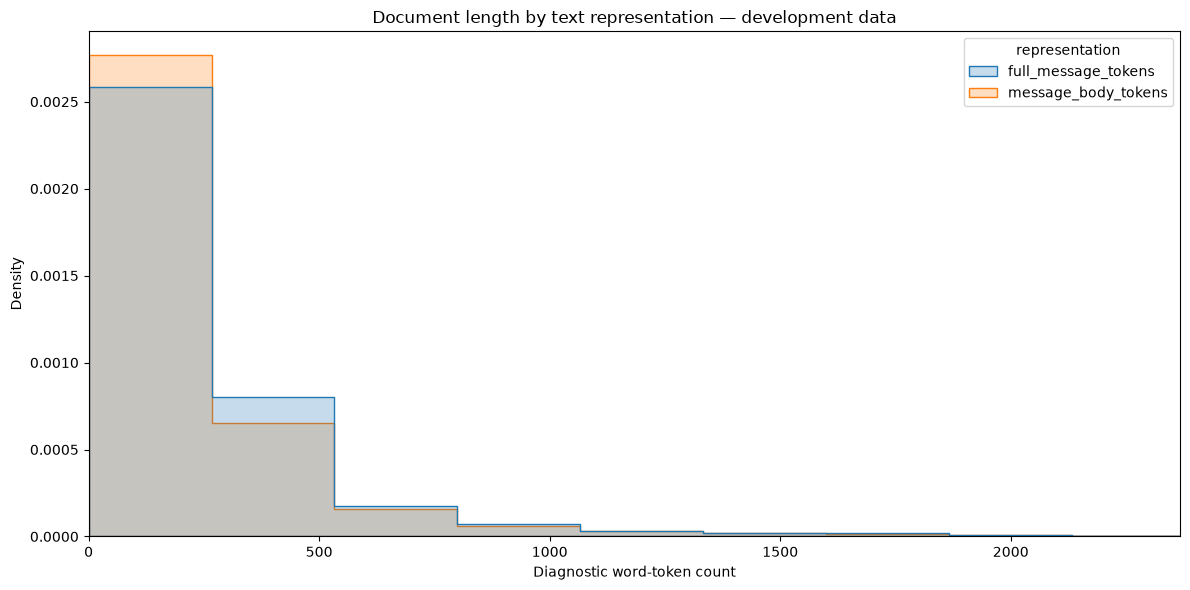

In [28]:
plot_data = profile.melt(
    id_vars=["partition"],
    value_vars=[
        "full_message_tokens",
        "message_body_tokens",
    ],
    var_name="representation",
    value_name="word-token count",
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=plot_data,
    x="word-token count",
    hue="representation",
    bins=60,
    element="step",
    stat="density",
    common_norm=False,
)

upper_limit = (
    profile[
        [
            "full_message_tokens",
            "message_body_tokens",
        ]
    ]
    .quantile(0.99)
    .max()
)

plt.xlim(0, upper_limit)
plt.title("Document length by text representation — development data")
plt.xlabel("Diagnostic word-token count")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

### Interpreting the Document-Length Findings

The descriptive statistics show a consistent difference between complete messages and message bodies.

For the training partition, the average full message contains approximately 326 diagnostic word tokens, compared with approximately 297 for the message body. The corresponding medians are 189 and 160 tokens.

Validation follows the same pattern. Its full messages average approximately 312 tokens, compared with approximately 283 for message bodies. The medians are 186 and 158 tokens.

The similar pattern across training and validation is useful: removing the header material reduces the measured length in both partitions rather than producing an effect isolated to one side of the development split.

The means are considerably higher than the medians, and the standard deviations are large. This indicates that the collection has a broad, right-skewed document-length distribution. Many messages are relatively short, while a smaller number are substantially longer.

This matters for later modelling. Long documents can increase memory requirements and processing time, particularly for neural networks and transformer models that operate on sequences of tokens. Any truncation strategy will therefore need to be justified and reported.

The class-level medians also vary. For example, several discussion-oriented groups have higher median token counts than some technical or marketplace groups. This is a descriptive characteristic of the corpus, not evidence that longer messages contain more useful information or that a particular class will be easier to predict.

The main finding is that the messages differ considerably in length, and the header material contributes to that length. The project should therefore compare the two representations rather than assume that one is automatically better.

### What the Distribution Plot Adds

The histogram makes the variation in document length easier to see. The full-message distribution is shifted towards longer documents, while the body-only representation generally contains fewer tokens.

Both distributions have a substantial spread. This reinforces the observation from the summary statistics that the dataset contains a mixture of short and very long messages.

The horizontal axis is limited to the 99th percentile to make the main body of the distribution easier to inspect. The most extreme documents are therefore not all displayed across their full length.

This is relevant to the later neural and transformer experiments. A sequence-length limit that is too short may discard useful information from longer messages; a limit that is too high may increase memory consumption and runtime unnecessarily.

The plot does not establish which representation will achieve better classification performance. That question requires controlled experiments using the same training and validation protocol.

## 9. Persist the Preprocessing Profile

The final step saves the descriptive profile and a compact record of the preprocessing decisions.

The row-level CSV contains document identifiers, labels, development partitions, character counts and diagnostic token counts. The JSON summary records the dataset, random seed, normalization choices, representations compared and the locations of the generated artifacts.

The split manifests remain under `data/interim/`, while the descriptive outputs are stored under `results/`.

The original raw messages are not copied into these result files. This keeps the outputs useful for subsequent analysis without creating another copy of the source corpus.

In [30]:
profile_output_dir = PROJECT_ROOT / "results" / "tables"
log_output_dir = PROJECT_ROOT / "results" / "logs"

profile_output_dir.mkdir(parents=True, exist_ok=True)
log_output_dir.mkdir(parents=True, exist_ok=True)

profile_csv_path = profile_output_dir / "preprocessing_profile.csv"
profile_json_path = log_output_dir / "preprocessing_profile_summary.json"

profile.to_csv(profile_csv_path, index=False)

profile_summary_payload = {
    "dataset": DATASET_CONFIG["name"],
    "random_seed": RANDOM_SEED,
    "validation_size_target": VALIDATION_SIZE,
    "text_preprocessing": {
        "unicode_normalization": "NFKC",
        "whitespace_normalization": True,
        "lowercase_default": False,
        "punctuation_removal": False,
        "stopword_removal": False,
        "stemming": False,
        "lemmatization": False,
        "representations_compared": [
            "full_message",
            "message_body",
        ],
    },
    "development_documents_profiled": int(len(profile)),
    "profile_columns": list(profile.columns),
    "split_manifest": str(SPLIT_OUTPUT_DIR / "preprocessing_split_manifest.json"),
    "profile_csv": str(profile_csv_path),
}

profile_json_path.write_text(
    json.dumps(
        profile_summary_payload,
        indent=2,
        ensure_ascii=False,
    )
    + "\n",
    encoding="utf-8",
)

print(f"Saved profile: {profile_csv_path}")
print(f"Saved summary: {profile_json_path}")

Saved profile: /home/nkululekocyrilcele/projects/topicsense-nlp/results/tables/preprocessing_profile.csv
Saved summary: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/preprocessing_profile_summary.json


## 10. Preprocessing Findings and Hand-off

### What This Phase Establishes

This phase establishes two reproducible development splits: one based on the original official training partition and another based on the training partition after the 10 substantive exact-duplicate exclusions.

Both splits preserve the separation between training and validation. The duplicate-connected groups identified by the available audits remain together, and all 20 classes are represented in both partitions.

The official test partition has not been used to fit preprocessing transformations or select models. The clean-test sensitivity track is defined separately, with 7,519 evaluation records remaining after the 13 implicated test records are excluded.

The text preparation remains conservative. Complete messages and message bodies are retained as alternative representations, with Unicode and whitespace normalization applied without automatically removing potentially useful content.

### Development-Set Characteristics

The document-length analysis shows that full messages are generally longer than their bodies in both training and validation.

The difference between the mean and median also shows that the development data contains a relatively small number of very long messages. These documents are relevant when selecting sequence-length limits for neural and transformer models.

The findings justify comparing text representations and documenting any truncation strategy. They do not establish that body-only text or full-message text will produce better classification performance.

### Remaining Limitations

The near-duplicate detector is approximate. It identifies candidate relationships using MinHash and verifies those candidates with Jaccard similarity. Similar documents that were not identified as candidates may therefore remain undetected.

Connected-component grouping is intentionally conservative. If one document is linked to a second, and that second document is linked to a third, all three are assigned to the same group. This is necessary to preserve the relationships identified by the audit, although it can influence the realised split ratio and class distribution.

The sensitivity tracks address substantive exact-body matches across the official training-test boundary. They do not remove every near-duplicate pair from evaluation. Those pairs remain a documented limitation when final evaluation results are interpreted.

Finally, the 20 Newsgroups labels represent destination newsgroups. A message can discuss several related subjects, so the labels should not be treated as proof that every document has one unambiguous semantic topic.

### Next Phase: Classical Machine-Learning Baselines

Notebook 03 establishes the classical machine-learning baselines using Multinomial Naive Bayes, Logistic Regression and Linear Support Vector Machines.

CountVectorizer and TF-IDF transformations are placed inside scikit-learn pipelines. Their learned vocabularies and feature weights must be fitted on training data only.

Validation data supports model comparison and development decisions. The official test partitions remain reserved for final evaluation, with the three evaluation tracks reported separately.

The objective is to establish reliable, reproducible baselines before introducing the additional computational cost and complexity of neural networks and transformer models.